# 🏛️ Viagens públicas: análise de custos e deslocamentos
**David dos Santos Boneli · SCTEC — Turma T6**  
**Camada Gold | PostgreSQL · Python · Pandas · Matplotlib**

---

## 🎯 Objetivo
Analisar os dados de viagens públicas da base de seis meses de 2025 disponibilizada pelo curso, respondendo às sete perguntas de negócio do projeto.

A **Parte A** apresenta três análises diretamente sobre a Silver. A **Parte B** consolida indicadores por meio de `JOIN` e `GROUP BY`, disponibilizando-os em tabela e VIEW no PostgreSQL para responder às quatro perguntas restantes.

## 📐 Critérios da análise
- **Custo líquido:** diárias + passagens + outros gastos − devolução.
- **Valores ausentes:** permanecem `NULL`; zero informado é preservado. Um componente monetário ausente resulta em custo total ausente. Somas e médias consideram os valores conhecidos, com cobertura indicada nas tabelas.
- **Duração:** diferença entre as datas final e inicial, em dias. Uma viagem no mesmo dia tem duração zero; datas ausentes resultam em duração ausente.
- **Destinos:** correspondem ao texto completo informado na base. Roteiros não são separados por cidade e seus custos não são rateados. Ausências e descrições de sigilo ficam fora desse ranking.
- **Duplicatas:** remoção de linhas integralmente iguais na Raw para compor a Silver. A Raw é preservada; o critério não permite distinguir eventos legítimos com conteúdo idêntico.
- **Indicadores financeiros:** pagamentos e custo líquido de viagens são medidas distintas.
- **Empates:** os rankings limitados utilizam o nome como desempate; a maior duração inclui todos os empates.

*Referência do enunciado: página 2 — perguntas de negócio; página 3 — Fase 3.*

---

In [1]:
from html import escape  # Protege os textos originais na exibição HTML
from decimal import Decimal  # Identifica valores monetários preservados como Decimal
from textwrap import fill, shorten  # Quebra e limita rótulos longos nos gráficos
import pandas as pd  # Organiza os resultados em tabelas
import matplotlib.pyplot as plt  # Desenha os gráficos
from matplotlib.ticker import FuncFormatter, MaxNLocator  # Formata os eixos
from IPython.display import display, Markdown, HTML  # Exibe tabelas e conclusões no notebook
from banco import conectar  # Usa as credenciais carregadas pelo config.py a partir do .env

plt.rcParams.update({"figure.dpi": 110, "font.size": 10})  # Define a aparência básica


ESTILO_TABELAS = '<style>\n.apresentacao-tabela {width:100%; max-width:100%; margin:12px 0 20px;}\n.apresentacao-tabela table {width:100% !important; max-width:100% !important; table-layout:fixed; border-collapse:collapse; font-size:12px; line-height:1.5; color:inherit;}\n.apresentacao-tabela th, .apresentacao-tabela td {white-space:normal !important; overflow-wrap:anywhere; word-break:normal; padding:9px 7px; vertical-align:top; text-align:left; border-bottom:1px solid #9aa8b544;}\n.apresentacao-tabela thead th {background:#28628e; color:white; font-weight:600;}\n.apresentacao-tabela tbody tr:nth-child(even) {background:#7895ad10;}\n</style>'  # Define largura fluida e quebra de texto nas tabelas


def consultar(comando):  # Recebe uma consulta SQL de leitura
    conexao = conectar()  # Abre uma conexão com transparencia
    try:  # Garante que a conexão seja fechada
        with conexao.cursor() as cursor:  # Fecha o cursor ao sair do bloco
            cursor.execute(comando)  # Executa a consulta
            colunas = [campo.name for campo in cursor.description]  # Obtém os nomes do resultado
            return pd.DataFrame(cursor.fetchall(), columns=colunas)  # Mantém Decimal nos valores monetários
    finally:  # Executa mesmo se a consulta falhar
        conexao.close()  # Libera a conexão


def moeda(valor):  # Recebe um valor para exibição em reais
    if valor is None or pd.isna(valor):  # Detecta ausência de informação
        return "Não informado"  # Evita apresentar ausência como zero
    return "R$ " + f"{valor:,.2f}".replace(",", "X").replace(".", ",").replace("X", ".")  # Usa formato brasileiro


def mostrar(dados):  # Recebe um DataFrame de resultados
    if dados.empty:  # Detecta falta de registros para a análise
        raise ValueError("A consulta não retornou registros analisáveis; confira a carga Silver.")  # Interrompe com contexto
    exibicao = dados.copy()  # Mantém os valores originais disponíveis para cálculos
    monetarias = {"custo_total", "custo_medio", "valor_total", "valor_gold", "valor_silver", "valor_medio", "total_pago", "valor_conhecido_sem_orgao_identificado"}  # Identifica medidas em reais pelo significado
    for coluna in dados.columns:  # Percorre as colunas do resultado
        if coluna in monetarias:  # Separa medidas monetárias das contagens
            exibicao[coluna] = dados[coluna].map(moeda)  # Formata os valores conhecidos em reais
        elif dados[coluna].map(lambda v: isinstance(v, (int, Decimal)) and not isinstance(v, bool)).any():  # Reconhece contagens e dias
            exibicao[coluna] = dados[coluna].map(lambda v: "Não informado" if pd.isna(v) else f"{int(v):,}".replace(",", "."))  # Exibe inteiros com separador brasileiro
    tabela_html = exibicao.fillna("Não informado").to_html(index=False, escape=True, border=0)  # Renderiza todas as colunas e os textos completos
    display(HTML(ESTILO_TABELAS + '<div class="apresentacao-tabela">' + tabela_html + '</div>'))  # Ajusta a tabela à largura disponível


def barras(dados, categoria, medida, titulo, eixo_x, monetario=False):  # Centraliza o desenho dos gráficos
    if dados.empty:  # Verifica se existem resultados para desenhar
        raise ValueError(f"Sem dados para o gráfico: {titulo}")  # Não gera um gráfico enganoso vazio
    plotagem = dados.iloc[::-1]  # Coloca o maior valor no alto do gráfico horizontal
    rotulos = [fill(shorten(str(v), width=140, placeholder="…"), width=48) for v in plotagem[categoria]]  # Quebra nomes longos
    valores = [float(v) for v in plotagem[medida]]  # Converte somente a cópia usada no desenho
    fig, ax = plt.subplots(figsize=(12, max(3.2, len(plotagem) * 0.75)))  # Ajusta o tamanho aos rótulos
    ax.barh(range(len(valores)), valores, color="#28628e", label=medida.replace("_", " "))  # Desenha as barras
    ax.set_yticks(range(len(rotulos)), labels=rotulos)  # Aplica os rótulos sem fundir categorias iguais
    ax.set_title(titulo, pad=15)  # Identifica a pergunta do gráfico
    ax.set_xlabel(eixo_x)  # Informa a unidade da medida
    ax.set_ylabel(categoria.replace("_", " ").capitalize())  # Identifica as categorias
    if monetario:  # Escolhe a apresentação de valores monetários
        ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: moeda(x)))  # Formata o eixo em reais
    else:  # Trata contagens e dias
        ax.xaxis.set_major_locator(MaxNLocator(integer=True))  # Usa marcações inteiras
    ax.grid(axis="x", alpha=0.2)  # Ajuda a comparar as barras
    ax.set_axisbelow(True)  # Mantém a grade atrás das barras
    ax.legend(loc="best")  # Explica a medida desenhada
    fig.tight_layout()  # Ajusta as margens
    plt.show()  # Exibe a figura no notebook
    plt.close(fig)  # Libera os recursos da figura

## 🔎 Cobertura e qualidade dos dados
A cobertura identifica quantas viagens possuem custo e duração calculáveis. `SUM` e `AVG` desconsideram valores `NULL`.

Durações e custos líquidos negativos são apresentados como sinais para investigação, preservando os valores registrados na Silver.

In [2]:
cobertura = consultar("""  -- Executa o SQL e guarda o resultado em um DataFrame
SELECT
    COUNT(*) AS total_viagens, -- Total disponível para análise
    COUNT(valor_total) AS custos_conhecidos, -- Base efetiva das somas e médias
    COUNT(*) - COUNT(valor_total) AS custos_ausentes, -- Viagens fora das medidas de custo
    COUNT(*) - COUNT(duracao_dias) AS duracoes_ausentes, -- Viagens sem duração calculável
    COUNT(*) FILTER (WHERE duracao_dias < 0) AS duracoes_negativas, -- Sinaliza datas invertidas
    COUNT(*) FILTER (WHERE valor_total < 0) AS custos_liquidos_negativos -- Sinaliza devolução maior que os gastos
FROM silver_viagem; -- Lê sem alterar a Silver
""")  # Encerra a consulta
mostrar(cobertura)  # Exibe os valores sem mudar sua precisão no banco


total_viagens,custos_conhecidos,custos_ausentes,duracoes_ausentes,duracoes_negativas,custos_liquidos_negativos
341.860,341.860,0,0,0,3


# 📊 Parte A — custos e duração das viagens
## 🏛️ 1. Quais são os cinco órgãos com maior custo total?
Cada viagem aparece uma vez. Agrupamos pelo código e nome do órgão superior e somamos seu custo líquido. Exibimos viagens com custo conhecido e ausente para deixar claro o alcance da soma.

In [3]:
orgaos = consultar("""  -- Executa o SQL e guarda o resultado em um DataFrame
SELECT
    cod_orgao_superior, -- Mantém códigos distintos separados
    nome_orgao_superior AS orgao, -- Identifica o órgão superior
    COUNT(*) AS quantidade_viagens, -- Conta todas as viagens do grupo
    COUNT(valor_total) AS custos_conhecidos, -- Conta valores que entram na soma
    COUNT(*) - COUNT(valor_total) AS custos_ausentes, -- Mostra a cobertura incompleta
    SUM(valor_total) AS custo_total -- Soma apenas os custos conhecidos
FROM silver_viagem -- Uma linha por viagem
GROUP BY cod_orgao_superior, nome_orgao_superior -- Define o agrupamento
HAVING COUNT(valor_total) > 0 -- Exige ao menos um custo conhecido
ORDER BY custo_total DESC, orgao, cod_orgao_superior -- Desempata pelo nome e código
LIMIT 5; -- Responde ao top cinco solicitado
""")  # Encerra a consulta
mostrar(orgaos)  # Exibe os valores sem mudar sua precisão no banco


cod_orgao_superior,orgao,quantidade_viagens,custos_conhecidos,custos_ausentes,custo_total
30000,Ministério da Justiça e Segurança Pública,75.742,75.742,0,"R$ 486.933.121,65"
52000,Ministério da Defesa,61.912,61.912,0,"R$ 156.070.304,49"
26000,Ministério da Educação,65.295,65.295,0,"R$ 111.291.349,34"
44000,Ministério do Meio Ambiente e Mudança do Clima,19.413,19.413,0,"R$ 49.697.710,16"
33000,Ministério da Previdência Social,8.190,8.190,0,"R$ 40.417.309,06"


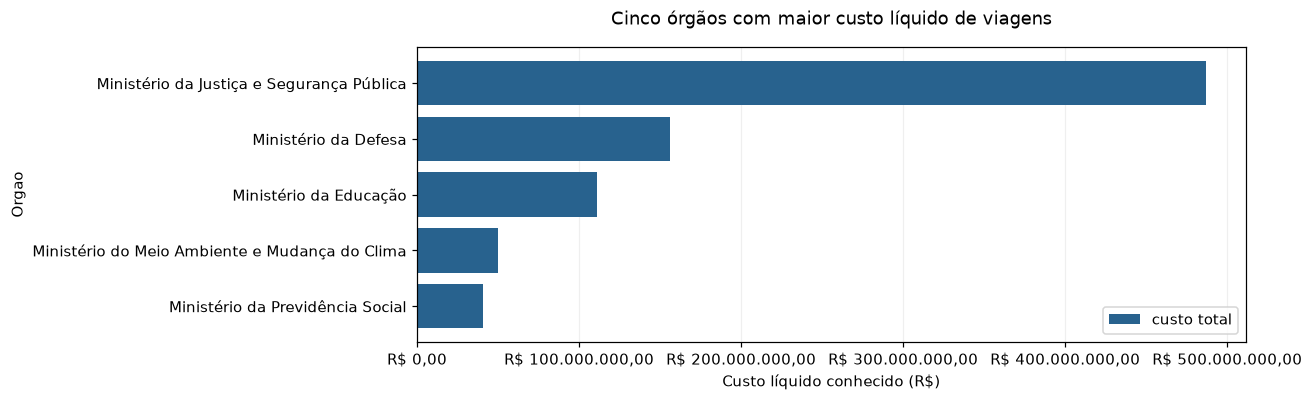

**Leitura:** Ministério da Justiça e Segurança Pública aparece na primeira posição, com R$ 486.933.121,65. Empatados nesse valor entre os cinco exibidos: 1. O ranking mede custo das viagens, não soma de pagamentos.

In [4]:
barras(orgaos, "orgao", "custo_total", "Cinco órgãos com maior custo líquido de viagens", "Custo líquido conhecido (R$)", monetario=True)  # Gráfico 1
lider = orgaos.iloc[0]  # Obtém o primeiro colocado do ranking
empatados = int((orgaos["custo_total"] == lider["custo_total"]).sum())  # Identifica empate entre os resultados exibidos
display(Markdown(f"**Leitura:** {lider['orgao']} aparece na primeira posição, com {moeda(lider['custo_total'])}. Empatados nesse valor entre os cinco exibidos: {empatados}. O ranking mede custo das viagens, não soma de pagamentos."))  # Explica a medida


## 📍 2. Quais são os três destinos com maior custo médio por viagem?
Agrupamos as viagens pelo **texto completo do campo de destinos**, excluindo ausências e descrições de sigilo. Um grupo pode conter várias cidades, portanto representa um roteiro informado, não uma cidade isolada.

A tabela e o gráfico utilizam rótulos curtos. Os detalhes de cada roteiro preservam o texto da fonte, inclusive suas repetições, sem alterar os grupos ou os custos.

In [5]:
destinos = consultar("""  -- Executa o SQL e guarda o resultado em um DataFrame
SELECT
    destinos AS destino, -- Preserva o texto completo do destino
    COUNT(*) AS quantidade_viagens, -- Mostra o tamanho do grupo
    COUNT(valor_total) AS custos_conhecidos, -- Define o denominador efetivo da média
    COUNT(*) - COUNT(valor_total) AS custos_ausentes, -- Explicita valores não usados
    AVG(valor_total) AS custo_medio -- Calcula a média por viagem com custo conhecido
FROM silver_viagem -- Usa o custo integral de cada viagem
WHERE destinos IS NOT NULL -- Exclui destinos ausentes
  AND TRIM(destinos) <> '' -- Exclui textos vazios
  AND destinos NOT ILIKE '%sigil%' -- Exclui menções a sigilo
  AND destinos NOT ILIKE '%informa%proteg%' -- Exclui a descrição de informação protegida
GROUP BY destinos -- Não divide nem rateia roteiros
HAVING COUNT(valor_total) > 0 -- Exige custo conhecido para calcular a média
ORDER BY custo_medio DESC, destino -- Ordena e desempata de forma definida
LIMIT 3; -- Responde ao top três solicitado
""")  # Encerra a consulta


def rotulo_roteiro(texto, posicao):  # Cria apenas um rótulo visual, sem modificar o agrupamento SQL
    cidades = [parte.strip().split("/")[0] for parte in texto.split(",")]  # Obtém nomes curtos para apresentação
    if len(cidades) <= 3:  # Mantém roteiros curtos reconhecíveis
        return f"Roteiro {posicao} · " + " · ".join(cidades)  # Identifica o grupo e suas cidades
    return f"Roteiro {posicao} · múltiplas cidades"  # Evita textos extensos na tabela e no gráfico


destinos_visual = destinos.copy()  # Preserva os dados da consulta para cálculos e conferência
destinos_visual["roteiro"] = [rotulo_roteiro(texto, i + 1) for i, texto in enumerate(destinos["destino"])]  # Identifica cada posição do ranking
resumo_destinos = destinos_visual[["roteiro", "quantidade_viagens", "custo_medio"]].rename(columns={"roteiro": "Roteiro informado", "quantidade_viagens": "Viagens", "custo_medio": "Custo médio por viagem"})  # Seleciona as três informações de leitura principal
resumo_destinos["Custo médio por viagem"] = resumo_destinos["Custo médio por viagem"].map(moeda)  # Formata a medida em reais sem alterar o original
mostrar(resumo_destinos)  # Exibe uma tabela compacta
for i, registro in destinos.iterrows():  # Apresenta a cobertura de cada grupo sem ampliar a tabela principal
    display(Markdown(f"**Roteiro {i + 1}:** {int(registro['custos_conhecidos'])} viagem(ns) com custo conhecido; {int(registro['custos_ausentes'])} com custo ausente."))  # Explicita a base da média

Roteiro informado,Viagens,Custo médio por viagem
Roteiro 1 · Abu Dabi · Riad · Rio de Janeiro,1,"R$ 245.852,80"
Roteiro 2 · múltiplas cidades,1,"R$ 216.729,36"
Roteiro 3 · múltiplas cidades,1,"R$ 207.220,14"


**Roteiro 1:** 1 viagem(ns) com custo conhecido; 0 com custo ausente.

**Roteiro 2:** 1 viagem(ns) com custo conhecido; 0 com custo ausente.

**Roteiro 3:** 1 viagem(ns) com custo conhecido; 0 com custo ausente.

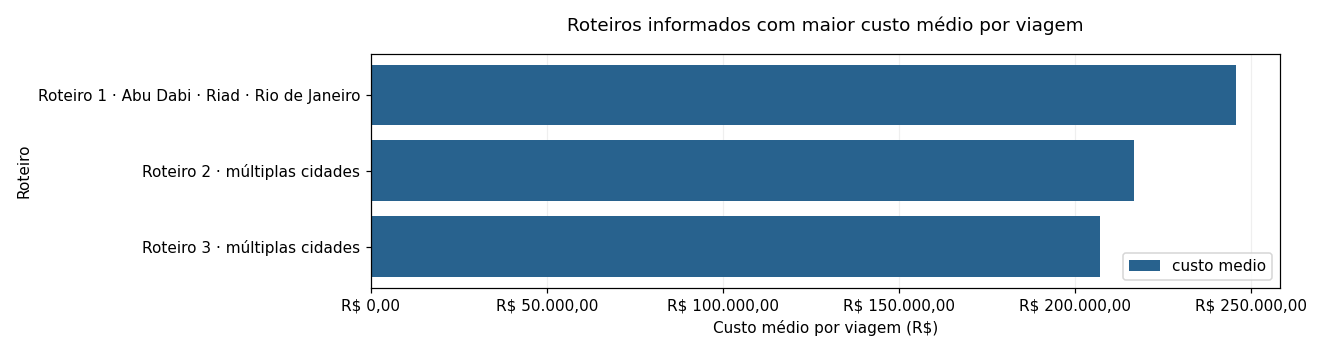

**Conclusão:** cada um dos três roteiros corresponde a uma única viagem. Assim, a média apresentada é o custo dessa viagem. Esses valores não estimam o custo individual de cada cidade nem um padrão recorrente de gastos.

### 🔎 Detalhes dos roteiros
Os textos abaixo são os destinos informados na fonte. Cidades repetidas foram preservadas; não representam novas linhas na tabela de resultados.

In [6]:
barras(destinos_visual, "roteiro", "custo_medio", "Roteiros informados com maior custo médio por viagem", "Custo médio por viagem (R$)", monetario=True)  # Usa os mesmos rótulos curtos da tabela
lider = destinos.iloc[0]  # Identifica o grupo com maior média
if destinos["quantidade_viagens"].eq(1).all():  # Verifica se cada grupo contém apenas uma viagem
    display(Markdown("**Conclusão:** cada um dos três roteiros corresponde a uma única viagem. Assim, a média apresentada é o custo dessa viagem. Esses valores não estimam o custo individual de cada cidade nem um padrão recorrente de gastos."))  # Explica o resultado observado
else:  # Mantém a interpretação válida em uma futura atualização da base
    display(Markdown(f"**Conclusão:** o Roteiro 1 lidera com média de {moeda(lider['custo_medio'])}. A quantidade de viagens indica o tamanho de cada grupo; os custos são do roteiro completo, sem rateio por cidade."))  # Contextualiza a comparação

display(Markdown("### 🔎 Detalhes dos roteiros\nOs textos abaixo são os destinos informados na fonte. Cidades repetidas foram preservadas; não representam novas linhas na tabela de resultados."))  # Distingue conteúdo do campo de duplicação de registros
for i, registro in destinos.iterrows():  # Associa cada detalhe ao mesmo rótulo da tabela e do gráfico
    texto_seguro = escape(str(registro["destino"]))  # Mantém os destinos como texto, sem interpretar HTML
    display(HTML(f"<details><summary><strong>Roteiro {i + 1} — ver destinos completos</strong></summary><p>{texto_seguro}</p></details>"))  # Recolhe o texto extenso e preserva acesso ao conteúdo integral

## 🗓️ 3. Qual é a viagem de maior duração e seu custo total?
Selecionamos todas as viagens cuja duração é igual à maior duração conhecida. O gráfico compara suas durações; o custo de cada uma fica na tabela. Isso evita misturar reais e dias no mesmo eixo.

In [7]:
longas = consultar("""  -- Executa o SQL e guarda o resultado em um DataFrame
SELECT
    id_viagem, -- Identifica a viagem sem expor o nome do viajante
    nome_orgao_superior AS orgao, -- Informa o órgão responsável
    destinos, -- Mantém o destino como registrado
    data_inicio, -- Mostra o início
    data_fim, -- Mostra o fim
    duracao_dias, -- Medida usada para encontrar a maior duração
    valor_total -- Responde também ao custo da viagem
FROM silver_viagem -- Consulta a Silver tratada
WHERE duracao_dias = (
    SELECT MAX(duracao_dias) FROM silver_viagem -- Inclui todos os empates no máximo
)
ORDER BY id_viagem; -- Apresenta empates de forma determinística
""")  # Encerra a consulta
mostrar(longas)  # Exibe os valores sem mudar sua precisão no banco


id_viagem,orgao,destinos,data_inicio,data_fim,duracao_dias,valor_total
0000000000020699856,Ministério da Previdência Social,Mogi Mirim/SP,2025-01-13,2026-01-31,383,"R$ 0,00"


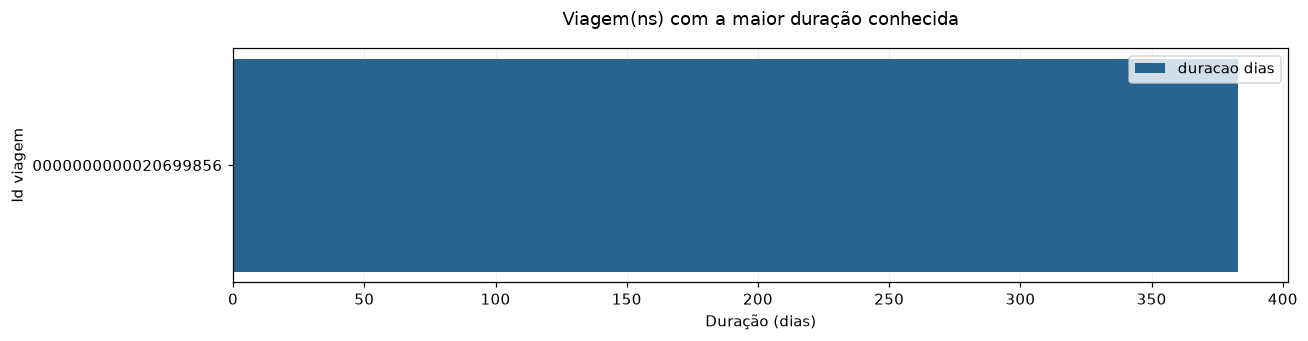

**Viagem 0000000000020699856:** 383 dias; custo líquido R$ 0,00. Duração mede diferença entre datas, não número de diárias pagas.

In [8]:
barras(longas, "id_viagem", "duracao_dias", "Viagem(ns) com a maior duração conhecida", "Duração (dias)")  # Gráfico 3
for _, viagem in longas.iterrows():  # Explica o custo de cada viagem empatada
    display(Markdown(f"**Viagem {viagem['id_viagem']}:** {int(viagem['duracao_dias'])} dias; custo líquido {moeda(viagem['valor_total'])}. Duração mede diferença entre datas, não número de diárias pagas."))  # Relaciona duração e custo


# 🗃️ Parte B — indicadores consolidados na Gold
## Estrutura dos indicadores
A Gold reúne dois tipos de indicadores, identificados pela coluna `familia`:

- **pagamento:** uma linha por órgão superior + órgão pagador + tipo de pagamento. Guarda quantidade de pagamentos, quantidade de valores conhecidos e soma dos valores.
- **trecho:** uma linha por órgão superior + meio de transporte + UF de destino. Guarda a quantidade de trechos.

Cada ramo faz **JOIN com silver_viagem** e depois **GROUP BY**. Os ramos são reunidos por `UNION ALL`, sem juntar pagamentos diretamente aos trechos. Essa estrutura evita multiplicar registros e valores pela associação entre pagamentos e trechos.

A média por tipo de pagamento será **soma dos valores / quantidade de valores conhecidos**, nunca média simples das médias dos grupos.

**VIEW:** executa a consulta sobre a Silver atual. **Tabela:** guarda uma fotografia dos indicadores no momento da atualização. A tabela é atualizada pela célula de construção; a VIEW consulta os dados atuais da Silver. Ambas são persistidas no PostgreSQL.

In [9]:
SQL_GOLD = """  -- Define a consulta agregada usada pela VIEW
SELECT
    'pagamento'::VARCHAR(20) AS familia, -- Identifica a unidade de análise
    v.cod_orgao_superior, -- Dimensão do órgão relacionado à viagem
    v.nome_orgao_superior, -- Nome dessa dimensão
    p.nome_orgao_pagador AS orgao_pagador, -- Dimensão necessária à pergunta 7
    p.tipo_pagamento, -- Dimensão necessária à pergunta 4
    NULL::VARCHAR(50) AS meio_transporte, -- Não pertence ao ramo de pagamentos
    NULL::VARCHAR(40) AS uf_destino, -- Não pertence ao ramo de pagamentos
    COUNT(*) AS quantidade_registros, -- Quantidade de pagamentos do grupo
    COUNT(p.valor) AS quantidade_valores, -- Denominador para a média ponderada
    SUM(p.valor) AS soma_valores -- Numerador para médias e totais
FROM silver_pagamento AS p -- Um registro por pagamento tratado
JOIN silver_viagem AS v ON v.id_viagem = p.id_viagem -- Relação muitos para um, sem multiplicação
GROUP BY v.cod_orgao_superior, v.nome_orgao_superior,
         p.nome_orgao_pagador, p.tipo_pagamento -- Define a granularidade do ramo
UNION ALL -- Mantém as duas famílias separadas
SELECT
    'trecho'::VARCHAR(20) AS familia, -- Identifica o ramo dos trechos
    v.cod_orgao_superior, -- Dimensão do órgão relacionado à viagem
    v.nome_orgao_superior, -- Nome dessa dimensão
    NULL::VARCHAR(255) AS orgao_pagador, -- Não pertence ao ramo de trechos
    NULL::VARCHAR(50) AS tipo_pagamento, -- Não pertence ao ramo de trechos
    t.meio_transporte, -- Dimensão necessária à pergunta 5
    t.destino_uf AS uf_destino, -- Dimensão necessária à pergunta 6
    COUNT(*) AS quantidade_registros, -- Conta cada trecho uma vez
    0::BIGINT AS quantidade_valores, -- Este ramo não mede pagamentos
    NULL::NUMERIC AS soma_valores -- Sem medida monetária para trechos
FROM silver_trecho AS t -- Um registro por trecho tratado
JOIN silver_viagem AS v ON v.id_viagem = t.id_viagem -- Relação muitos para um
GROUP BY v.cod_orgao_superior, v.nome_orgao_superior,
         t.meio_transporte, t.destino_uf -- Define a granularidade do ramo
"""  # Encerra a definição da consulta

conexao = conectar()  # Abre uma conexão para construir os objetos Gold
try:  # Trata a atualização como uma única transação
    with conexao.cursor() as cursor:  # Fecha o cursor ao sair
        cursor.execute("CREATE OR REPLACE VIEW vw_gold_indicadores AS " + SQL_GOLD)  # Cria a VIEW no PostgreSQL
        cursor.execute("CREATE TABLE IF NOT EXISTS gold_indicadores AS SELECT * FROM vw_gold_indicadores WITH NO DATA")  # Cria a tabela se necessário
        cursor.execute("TRUNCATE TABLE gold_indicadores")  # Remove a fotografia anterior sem acumular cópias
        cursor.execute("INSERT INTO gold_indicadores SELECT * FROM vw_gold_indicadores")  # Atualiza a fotografia
    conexao.commit()  # Confirma a construção somente após todos os comandos
    print("Tabela gold_indicadores e VIEW vw_gold_indicadores atualizadas.")  # Informa o sucesso
except Exception:  # Captura falhas na construção
    conexao.rollback()  # Preserva a versão anterior se houver erro
    raise  # Mostra a causa original
finally:  # Executa em qualquer resultado
    conexao.close()  # Fecha a conexão de construção


Tabela gold_indicadores e VIEW vw_gold_indicadores atualizadas.


## ✅ Validação da camada Gold
Comparamos as contagens e os valores conhecidos da Gold com a Silver. Também verificamos se tabela e VIEW contêm as mesmas linhas nesta execução. A tolerância para diferença monetária é zero: no banco usamos NUMERIC, não float.

In [10]:
conferencia_gold = consultar("""  -- Executa o SQL e guarda o resultado em um DataFrame
SELECT
    (SELECT SUM(quantidade_registros) FROM gold_indicadores WHERE familia = 'pagamento') AS pagamentos_gold, -- Soma sem duplicação
    (SELECT COUNT(*) FROM silver_pagamento) AS pagamentos_silver, -- Total de referência
    (SELECT SUM(soma_valores) FROM gold_indicadores WHERE familia = 'pagamento') AS valor_gold, -- Soma agregada conhecida
    (SELECT SUM(valor) FROM silver_pagamento) AS valor_silver, -- Soma de referência
    (SELECT SUM(quantidade_registros) FROM gold_indicadores WHERE familia = 'trecho') AS trechos_gold, -- Soma dos trechos
    (SELECT COUNT(*) FROM silver_trecho) AS trechos_silver; -- Total de referência
""")  # Encerra a consulta
mostrar(conferencia_gold)  # Exibe os valores sem mudar sua precisão no banco


pagamentos_gold,pagamentos_silver,valor_gold,valor_silver,trechos_gold,trechos_silver
568.811,568.811,"R$ 1.008.939.360,78","R$ 1.008.939.360,78",763.349,763.349


In [11]:
checagem = conferencia_gold.iloc[0]  # Seleciona a única linha de conferência
assert int(checagem["pagamentos_gold"]) == int(checagem["pagamentos_silver"]), "Contagem de pagamentos divergente."  # Confere pagamentos
assert checagem["valor_gold"] == checagem["valor_silver"], "Soma de pagamentos divergente."  # Confere valores sem float
assert int(checagem["trechos_gold"]) == int(checagem["trechos_silver"]), "Contagem de trechos divergente."  # Confere trechos
iguais = consultar("""  -- Procura linhas diferentes entre a tabela e a VIEW
SELECT COUNT(*) AS diferencas FROM (
    (SELECT * FROM gold_indicadores EXCEPT ALL SELECT * FROM vw_gold_indicadores) -- Diferenças da tabela para a VIEW
    UNION ALL -- Reúne as duas direções de comparação
    (SELECT * FROM vw_gold_indicadores EXCEPT ALL SELECT * FROM gold_indicadores) -- Diferenças da VIEW para a tabela
) AS comparacao; -- Conta as diferenças
""")  # Encerra a comparação
assert int(iguais.iloc[0]["diferencas"]) == 0, "Tabela e VIEW estão diferentes; atualize a Gold."  # Exige igualdade nesta execução
print("Conferências aprovadas: contagens, soma de pagamentos e equivalência tabela/VIEW.")  # Informa o resultado


Conferências aprovadas: contagens, soma de pagamentos e equivalência tabela/VIEW.


## 💳 4. Qual tipo de pagamento tem maior valor médio?
Usamos apenas a família pagamento. Reagrupamos os valores de todos os órgãos por tipo e dividimos a soma conhecida pelo número de valores conhecidos. A tabela apresenta as médias por categoria de pagamento.

In [22]:
tipos = consultar("""  -- Executa o SQL e guarda o resultado em um DataFrame
SELECT
    tipo_pagamento, -- Categoria analisada
    SUM(quantidade_registros) AS quantidade_pagamentos, -- Total de registros do tipo
    SUM(quantidade_valores) AS valores_conhecidos, -- Denominador da média
    SUM(quantidade_registros) - SUM(quantidade_valores) AS valores_ausentes, -- Cobertura da medida
    SUM(soma_valores) / NULLIF(SUM(quantidade_valores), 0) AS valor_medio -- Evita média de médias e divisão por zero
FROM gold_indicadores -- Usa a tabela agregada
WHERE familia = 'pagamento' -- Não mistura pagamentos com trechos
GROUP BY tipo_pagamento -- Reúne o tipo entre todos os órgãos
HAVING SUM(quantidade_valores) > 0 -- Exige algum valor conhecido
ORDER BY valor_medio DESC, tipo_pagamento; -- A primeira linha responde à pergunta
""")  # Encerra a consulta
mostrar(tipos)  # Exibe os valores sem mudar sua precisão no banco


tipo_pagamento,quantidade_pagamentos,valores_conhecidos,valores_ausentes,valor_medio
PASSAGEM,186.008,186.008,0,"R$ 1.856,78"
DIÁRIAS,366.351,366.351,0,"R$ 1.797,55"
Serviço correlato: seguro,4.882,4.882,0,"R$ 447,72"
RESTITUIÇÃO,11.570,11.570,0,"R$ 245,69"


In [13]:
maximo = tipos["valor_medio"].max()  # Obtém a maior média conhecida
vencedores = tipos.loc[tipos["valor_medio"] == maximo, "tipo_pagamento"].tolist()  # Inclui todos os empates
display(Markdown(f"**Resposta:** {', '.join(map(str, vencedores))}; maior média de {moeda(maximo)} por pagamento com valor conhecido."))  # Apresenta a resposta baseada no resultado


**Resposta:** PASSAGEM; maior média de R$ 1.856,78 por pagamento com valor conhecido.

## 🚌 5. Qual meio de transporte é mais usado nos trechos?
Somamos as quantidades de trechos de cada meio, sem usar a quantidade de viagens como se fosse quantidade de trechos. Categorias ausentes são exibidas como “Não informado”, separadas dos meios identificados. O gráfico mostra até dez categorias; a tabela traz todas.

In [14]:
transportes = consultar("""  -- Executa o SQL e guarda o resultado em um DataFrame
SELECT
    COALESCE(meio_transporte, 'Não informado') AS meio_transporte, -- Identifica categorias ausentes
    SUM(quantidade_registros) AS quantidade_trechos -- Conta trechos, não viagens
FROM gold_indicadores -- Usa a fotografia agregada
WHERE familia = 'trecho' -- Seleciona apenas essa unidade de análise
GROUP BY COALESCE(meio_transporte, 'Não informado') -- Agrupa por meio
ORDER BY quantidade_trechos DESC, meio_transporte; -- Ordena do mais frequente ao menos frequente
""")  # Encerra a consulta
mostrar(transportes)  # Exibe os valores sem mudar sua precisão no banco


meio_transporte,quantidade_trechos
Veículo Oficial,386.424
Aéreo,232.666
Rodoviário,64.970
Veículo Próprio,42.846
Inválido,26.659
Fluvial,8.429
Ferroviário,874
Marítimo,481


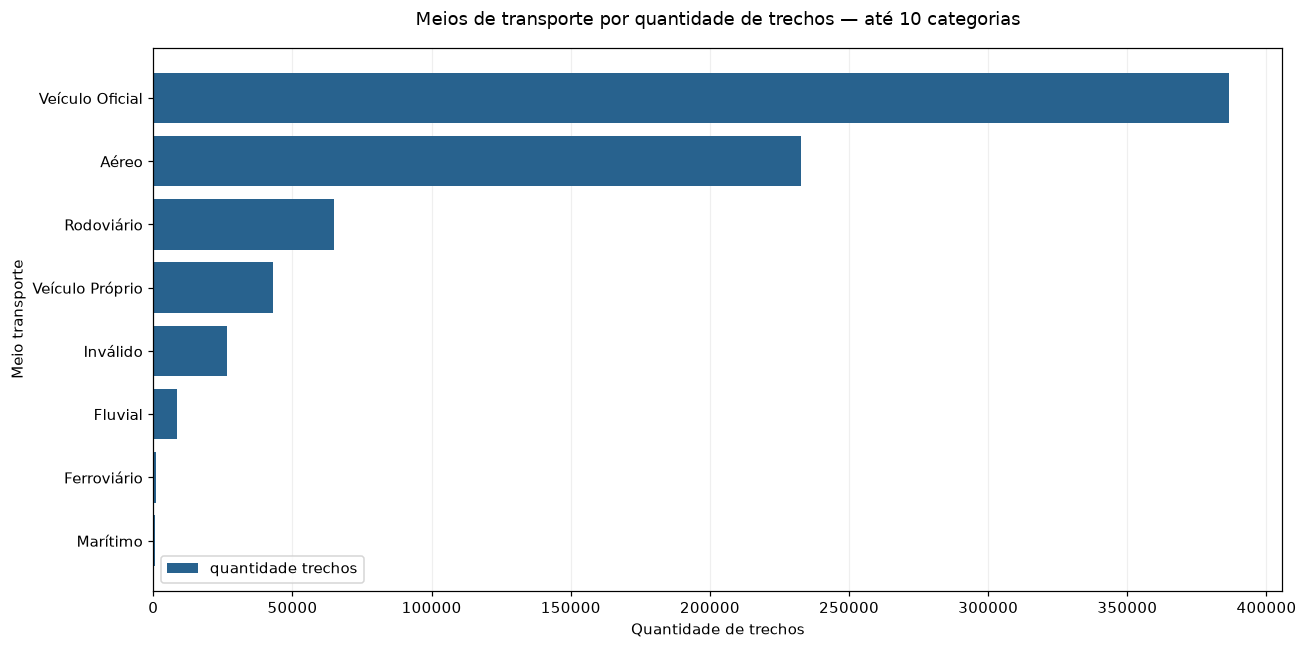

**Resposta:** categoria(s) mais frequente(s): Veículo Oficial, com 386.424 trechos cada. Se a categoria for não informada ou protegida, isso representa uma limitação de identificação.

In [15]:
barras(transportes.head(10), "meio_transporte", "quantidade_trechos", "Meios de transporte por quantidade de trechos — até 10 categorias", "Quantidade de trechos")  # Gráfico 4
maximo = transportes["quantidade_trechos"].max()  # Encontra a maior contagem
vencedores = transportes.loc[transportes["quantidade_trechos"] == maximo, "meio_transporte"].tolist()  # Inclui empates
display(Markdown(f"**Resposta:** categoria(s) mais frequente(s): {', '.join(map(str, vencedores))}, com {format(int(maximo), ',').replace(',', '.')} trechos cada. Se a categoria for não informada ou protegida, isso representa uma limitação de identificação."))  # Interpreta o resultado sem inventar o meio


## 🗺️ 6. Qual UF de destino aparece em mais trechos?
Agrupamos a UF conforme informada em `silver_trecho.destino_uf`. Ausências e descrições explícitas de sigilo/proteção não identificam uma UF e são excluídas do ranking; contabilizamos essas exclusões separadamente. Não inferimos UF a partir do nome de cidade. A tabela mantém todas as categorias elegíveis, permitindo revisar rótulos da base.

In [16]:
cobertura_ufs = consultar("""  -- Executa o SQL e guarda o resultado em um DataFrame
SELECT
    COALESCE(SUM(quantidade_registros), 0) AS trechos_sem_uf_identificada -- Quantifica os registros fora do ranking
FROM gold_indicadores -- Usa a mesma base agregada
WHERE familia = 'trecho' -- Seleciona trechos
  AND (uf_destino IS NULL OR TRIM(uf_destino) = ''
       OR uf_destino ILIKE '%sigil%' OR uf_destino ILIKE '%informa%proteg%'); -- Detecta ausência ou proteção explícita
""")  # Encerra a consulta
mostrar(cobertura_ufs)  # Exibe os valores sem mudar sua precisão no banco


trechos_sem_uf_identificada
14.742


In [17]:
ufs = consultar("""  -- Executa o SQL e guarda o resultado em um DataFrame
SELECT
    uf_destino, -- Mantém a classificação conforme a base
    SUM(quantidade_registros) AS quantidade_trechos -- Conta ocorrências de destino nos trechos
FROM gold_indicadores -- Usa a fotografia agregada
WHERE familia = 'trecho' -- Seleciona trechos
  AND uf_destino IS NOT NULL AND TRIM(uf_destino) <> '' -- Exclui ausências
  AND uf_destino NOT ILIKE '%sigil%' -- Exclui sigilo explícito
  AND uf_destino NOT ILIKE '%informa%proteg%' -- Exclui informação protegida
GROUP BY uf_destino -- Reúne os registros da mesma categoria
ORDER BY quantidade_trechos DESC, uf_destino; -- Ordena por frequência
""")  # Encerra a consulta
mostrar(ufs)  # Exibe os valores sem mudar sua precisão no banco


uf_destino,quantidade_trechos
São Paulo,82.722
Distrito Federal,79.962
Minas Gerais,50.965
Rio de Janeiro,44.197
Paraná,42.603
Pará,40.044
Rio Grande do Sul,38.684
Mato Grosso do Sul,30.516
Bahia,28.375
Pernambuco,28.372


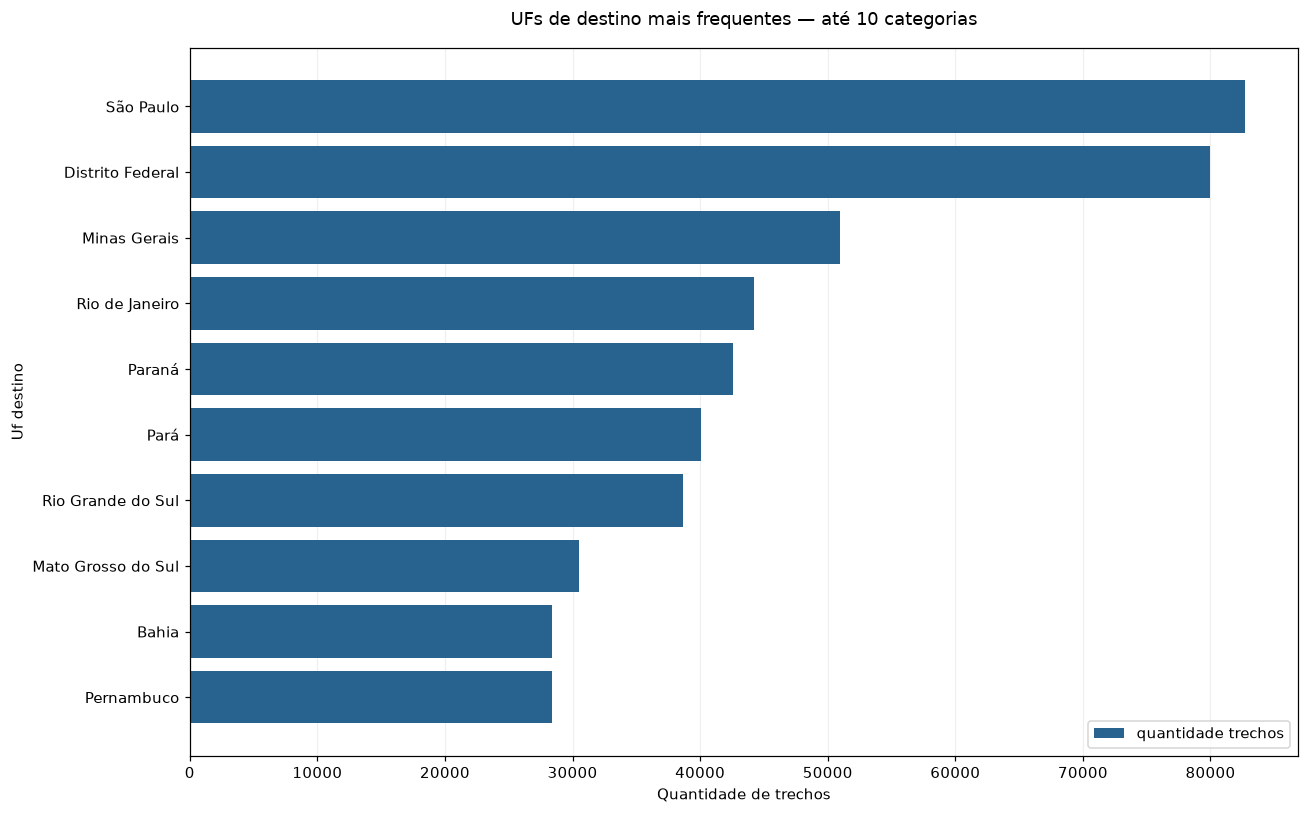

**Resposta:** São Paulo, com 82.722 trechos cada, considerando as categorias de UF identificadas conforme a base.

In [18]:
barras(ufs.head(10), "uf_destino", "quantidade_trechos", "UFs de destino mais frequentes — até 10 categorias", "Quantidade de trechos")  # Gráfico 5
maximo = ufs["quantidade_trechos"].max()  # Encontra a maior contagem
vencedores = ufs.loc[ufs["quantidade_trechos"] == maximo, "uf_destino"].tolist()  # Inclui empates
display(Markdown(f"**Resposta:** {', '.join(map(str, vencedores))}, com {format(int(maximo), ',').replace(',', '.')} trechos cada, considerando as categorias de UF identificadas conforme a base."))  # Explica o recorte adotado


## 🏦 7. Qual órgão pagou mais no total?
Usamos o **nome do órgão pagador**, disponível no dicionário Silver de pagamentos. Não confundimos esse órgão com o órgão superior da pergunta 1. Agrupamos pelo nome porque a Silver definida no PDF não possui código do órgão pagador; órgãos homônimos não podem ser separados por esse modelo. Ausência ou sigilo explícito não identifica um órgão e fica fora do ranking, com cobertura mostrada separadamente.

In [19]:
cobertura_pagadores = consultar("""  -- Executa o SQL e guarda o resultado em um DataFrame
SELECT
    COALESCE(SUM(quantidade_registros), 0) AS pagamentos_sem_orgao_identificado, -- Conta pagamentos fora do ranking
    SUM(soma_valores) AS valor_conhecido_sem_orgao_identificado -- Mostra o valor conhecido excluído
FROM gold_indicadores -- Usa a mesma fotografia
WHERE familia = 'pagamento' -- Seleciona pagamentos
  AND (orgao_pagador IS NULL OR TRIM(orgao_pagador) = ''
       OR orgao_pagador ILIKE '%sigil%' OR orgao_pagador ILIKE '%informa%proteg%'); -- Identifica ausências e proteção
""")  # Encerra a consulta
mostrar(cobertura_pagadores)  # Exibe os valores sem mudar sua precisão no banco


pagamentos_sem_orgao_identificado,valor_conhecido_sem_orgao_identificado
86.878,"R$ 170.659.883,35"


In [20]:
pagadores = consultar("""  -- Executa o SQL e guarda o resultado em um DataFrame
SELECT
    orgao_pagador, -- Identifica quem efetuou o pagamento
    SUM(quantidade_registros) AS quantidade_pagamentos, -- Conta os pagamentos do órgão
    SUM(quantidade_registros) - SUM(quantidade_valores) AS valores_ausentes, -- Explicita a cobertura
    SUM(soma_valores) AS total_pago -- Soma os valores conhecidos, sem multiplicar por trechos
FROM gold_indicadores -- Usa a fotografia agregada
WHERE familia = 'pagamento' -- Seleciona a família correta
  AND orgao_pagador IS NOT NULL AND TRIM(orgao_pagador) <> '' -- Exclui órgãos ausentes
  AND orgao_pagador NOT ILIKE '%sigil%' -- Exclui sigilo explícito
  AND orgao_pagador NOT ILIKE '%informa%proteg%' -- Exclui informação protegida
GROUP BY orgao_pagador -- Agrupa pelo nome disponível no modelo Silver
HAVING SUM(quantidade_valores) > 0 -- Exige ao menos um valor conhecido
ORDER BY total_pago DESC, orgao_pagador; -- A primeira linha responde à pergunta
""")  # Encerra a consulta
mostrar(pagadores)  # Exibe os valores sem mudar sua precisão no banco


orgao_pagador,quantidade_pagamentos,valores_ausentes,total_pago
Fundo Nacional de Segurança Pública,53.440,0,"R$ 141.911.719,64"
Comando da Aeronáutica,45.962,0,"R$ 81.180.823,06"
Comando do Exército,22.056,0,"R$ 35.901.379,45"
Instituto Nacional do Seguro Social,17.899,0,"R$ 35.385.354,57"
Ministério da Gestão e da Inovação em Serviços Públicos - Unidades com vínculo direto,20.136,0,"R$ 34.640.016,36"
Instituto Brasileiro do Meio Ambiente e dos Recursos Naturais Renováveis,16.581,0,"R$ 31.010.870,85"
Ministério das Relações Exteriores - Unidades com vínculo direto,3.685,0,"R$ 25.589.924,60"
Receita Federal do Brasil,18.833,0,"R$ 23.548.336,51"
Ministério da Agricultura e Pecuária - Unidades com vínculo direto,15.757,0,"R$ 22.343.023,69"
Ministério da Defesa - Unidades com vínculo direto,9.192,0,"R$ 20.468.160,01"


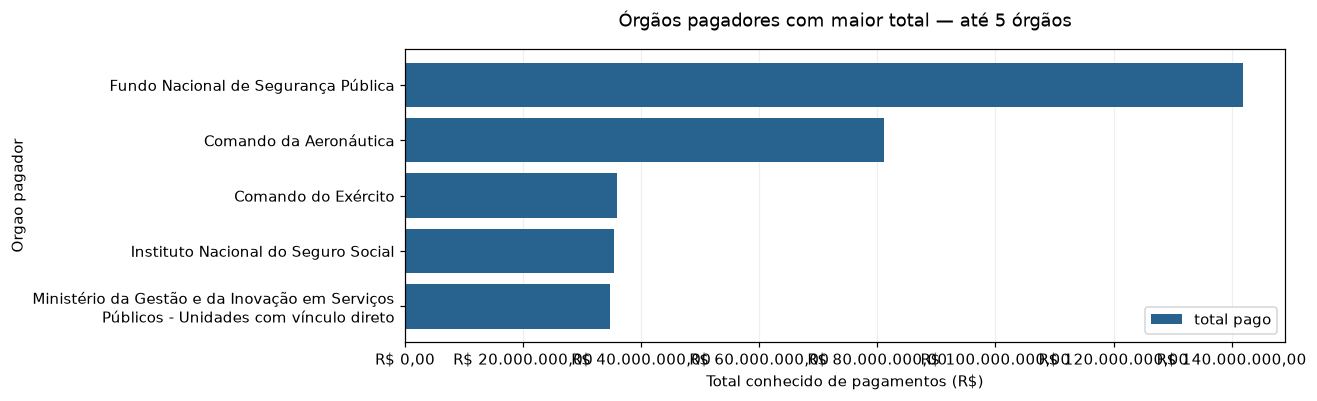

**Resposta:** Fundo Nacional de Segurança Pública, com R$ 141.911.719,64 cada em pagamentos conhecidos. Esse total não é o custo líquido de viagens calculado na pergunta 1.

In [21]:
barras(pagadores.head(5), "orgao_pagador", "total_pago", "Órgãos pagadores com maior total — até 5 órgãos", "Total conhecido de pagamentos (R$)", monetario=True)  # Gráfico 6
maximo = pagadores["total_pago"].max()  # Encontra o maior total
vencedores = pagadores.loc[pagadores["total_pago"] == maximo, "orgao_pagador"].tolist()  # Inclui todos os empates
display(Markdown(f"**Resposta:** {', '.join(map(str, vencedores))}, com {moeda(maximo)} cada em pagamentos conhecidos. Esse total não é o custo líquido de viagens calculado na pergunta 1."))  # Diferencia as duas medidas de negócio


# 📝 Síntese dos resultados

| Pergunta | Principal resultado |
|:--|:--|
| Órgão superior com maior custo líquido | **Ministério da Justiça e Segurança Pública:** R$ 486.933.121,65 em 75.742 viagens. |
| Destino informado com maior custo médio | **Abu Dabi/Emirados Árabes, Riad/Arábia Saudita, Rio de Janeiro/RJ:** R$ 245.852,80, referente a uma viagem. |
| Viagem de maior duração | **0000000000020699856:** 383 dias, de 13/01/2025 a 31/01/2026, com custo líquido registrado de R$ 0,00. |
| Tipo de pagamento com maior média | **PASSAGEM:** R$ 1.856,78 por pagamento. |
| Meio de transporte mais frequente | **Veículo Oficial:** 386.424 trechos. |
| UF de destino mais frequente | **São Paulo:** 82.722 trechos. |
| Órgão identificado com maior total pago | **Fundo Nacional de Segurança Pública:** R$ 141.911.719,64. |

Os resultados distinguem **custo líquido de viagens**, **valor dos pagamentos** e **quantidade de trechos**. São indicadores com unidades e critérios de agregação próprios, portanto seus totais não devem ser comparados como medidas equivalentes.

## ⚠️ Limitações e pontos de atenção
- **Recorte:** os rankings se referem à base de seis meses de 2025 disponibilizada pelo curso. As datas registradas nas viagens podem ultrapassar esse período, como no caso da maior duração; não há extrapolação para o ano completo.
- **Médias por destino:** os três primeiros grupos possuem uma viagem cada. Os valores caracterizam esses registros, sem demonstrar um padrão recorrente de custo por cidade ou roteiro.
- **Qualidade dos registros:** todas as 341.860 viagens possuem custo e duração calculáveis. Há três custos líquidos negativos. A viagem de 383 dias com custo líquido zero também merece conferência na fonte; esses resultados foram preservados e não permitem concluir irregularidade.
- **Identificação de destinos:** 14.742 trechos sem UF identificada foram excluídos do ranking. A base também contém 29 trechos com a categoria “Inválido”, exibida separadamente, sem atribuição a um estado.
- **Identificação dos pagadores:** 86.878 pagamentos, somando R$ 170.659.883,35, não possuem órgão identificável segundo os critérios adotados e ficam fora do ranking nominal. Portanto, o vencedor corresponde aos órgãos identificados.
- **Modelo e tratamento:** os destinos mantêm o texto integral da fonte; os órgãos pagadores são agrupados pelo nome; a deduplicação usa igualdade integral da linha Raw. Essas escolhas delimitam a interpretação dos resultados.

## ✅ Integridade da consolidação
A conferência confirmou **568.811 pagamentos**, com soma de **R$ 1.008.939.360,78**, e **763.349 trechos**, sem divergência entre a Silver e a Gold. A tabela `gold_indicadores` e a VIEW `vw_gold_indicadores` apresentaram as mesmas linhas na execução registrada.

*A síntese corresponde aos resultados salvos neste notebook. Uma atualização da base requer nova conferência das conclusões.*